# 06 - Simulation study: bias, coverage and failure modes of the reliance estimators

Real data cannot tell us the *true* reliance of a model. Here we simulate patients, images and a model with
**known** evidence weight, so we can check whether the estimators recover the truth.

**Data-generating process (one anchor per patient, as in notebooks 03-05)**
- Each patient has a trajectory with nuisance drift: nuisance z(t) = tau_i * t, where the trend tau_i is
  **correlated with the direction of the label change** (patients who develop effusion also change in other ways -
  exactly what D_ctrl > 0 showed on NIH).
- Four images: anchor a (time 0), flip partner f (time k, opposite label), control pair s1, s (same label, times u and u + k').
- Model score: logit p = beta_e * y + beta_z * z + beta_m * m + c + eps, with eps ~ N(0, sigma^2) per image.
  beta_e = true evidence weight, beta_z = nuisance weight, m = an optional marker, c = an offset (saturation / text override).

**True estimand** (ideal intervention): change only the evidence, hold nuisance fixed:
R* = E[(p(y_f, z_a) - p(y_a, z_a)) * (y_f - y_a)] (probability scale) and the analogous sign version.
Computed by Monte Carlo with 10^6 draws.

**Estimators compared**
1. **naive** D_flip (no control),
2. **mismatched control** (same-label partner at a *different* time gap - the notebook 01/02 design),
3. **exact-gap pair control** R_dir = D_flip - D_ctrl (our estimator), and R_sign.

**Scenarios**
- S1 null model (beta_e = 0) with drift -> false-positive rate;
- S2 coverage of 95% bootstrap CIs across effect sizes and sample sizes;
- S3 label noise (a fraction q of observed flips are spurious) -> attenuation;
- S4 calibration / saturation (temperature, offset) -> R_dir vs R_sign;
- S5 shortcut marker held fixed vs following the label.

CPU only; about 5-10 minutes. No inputs needed.

In [1]:
import numpy as np, pandas as pd, time
import matplotlib.pyplot as plt
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
OUT = "."
sig = lambda x: 1 / (1 + np.exp(-x))
T0 = time.time()

def simulate(n, beta_e=1.0, beta_z=0.5, kappa=0.3, sigma=1.0, offset=0.0, temp=1.0, q_noise=0.0,
             control="pair", marker=None, beta_m=0.0, rho=0.5, seed=0):
    """Returns per-anchor scores for n patients (one anchor each).
    control: 'pair' (exact gap, ours), 'mismatch' (different gap), 'none'.
    marker: None, 'fixed' (marker off on all 4 images), 'follow' (marker on w.p. rho if label 1, 1-rho if 0).
    q_noise: fraction of observed flips that are spurious (true labels equal)."""
    rng = np.random.default_rng(seed)
    ya = rng.integers(0, 2, n)                     # observed anchor label (balanced directions)
    dy = 1 - 2 * ya                                # +1 absent->present, -1 present->absent
    spurious = rng.random(n) < q_noise             # observed flip, but true label did not change
    ya_true, yf_true = ya.copy(), np.where(spurious, ya, 1 - ya)
    tau = kappa * dy + rng.normal(0, 0.3, n)       # nuisance trend correlated with the direction of change
    k = rng.integers(1, 6, n)                      # flip gap
    u = rng.integers(-3, 4, n)                     # control pair start time
    if control == "mismatch":
        k2 = np.maximum(1, k - rng.integers(1, 4, n))   # control gap systematically shorter (as on NIH: 1.95 vs 3.55)
    else:
        k2 = k
    t = {"a": np.zeros(n), "f": k.astype(float), "s1": u.astype(float), "s": (u + k2).astype(float)}
    y = {"a": ya_true, "f": yf_true, "s1": ya_true, "s": ya_true}
    p = {}
    for r in t:
        m = np.zeros(n)
        if marker == "follow":
            m = np.where(y[r] == 1, rng.random(n) < rho, rng.random(n) < 1 - rho).astype(float)
        logit = beta_e * y[r] + beta_z * tau * t[r] + beta_m * m + offset + rng.normal(0, sigma, n)
        p[r] = sig(logit / temp)
    D_flip = (p["f"] - p["a"]) * dy
    D_ctrl = (p["s"] - p["s1"]) * dy if control != "none" else np.zeros(n)
    S_flip = np.sign(p["f"] - p["a"]) * dy
    S_ctrl = np.sign(p["s"] - p["s1"]) * dy if control != "none" else np.zeros(n)
    return pd.DataFrame({"D_flip": D_flip, "D_ctrl": D_ctrl, "R_dir": D_flip - D_ctrl, "R_sign": S_flip - S_ctrl})

def truth(beta_e=1.0, beta_z=0.5, kappa=0.3, sigma=1.0, offset=0.0, temp=1.0, n=1_000_000, seed=123, **_):
    """Ideal intervention: change only the evidence, nuisance fixed at the anchor's value (t = 0),
    independent image noise in both arms (as in the real pairs)."""
    rng = np.random.default_rng(seed)
    ya = rng.integers(0, 2, n); dy = 1 - 2 * ya
    base = offset
    pa = sig((beta_e * ya + base + rng.normal(0, sigma, n)) / temp)
    pf = sig((beta_e * (1 - ya) + base + rng.normal(0, sigma, n)) / temp)
    pa2 = sig((beta_e * ya + base + rng.normal(0, sigma, n)) / temp)       # same evidence, fresh noise (control)
    pa3 = sig((beta_e * ya + base + rng.normal(0, sigma, n)) / temp)
    R = ((pf - pa) * dy).mean() - ((pa3 - pa2) * dy).mean()
    Rs = (np.sign(pf - pa) * dy).mean() - (np.sign(pa3 - pa2) * dy).mean()
    return R, Rs

def boot_ci(x, B=1000, rng=None):
    rng = rng or np.random.default_rng(0)
    idx = rng.integers(0, len(x), (B, len(x)))
    b = x[idx].mean(1)
    return x.mean(), np.percentile(b, 2.5), np.percentile(b, 97.5)

def run(cfg, n, reps=300, cols=("R_dir", "R_sign"), B=1000):
    Rt, Rst = truth(**cfg)
    tr = {"R_dir": Rt, "R_sign": Rst, "D_flip": Rt}
    rows = []
    rng = np.random.default_rng(1)
    for c in cols:
        est, cover, width, rej = [], [], [], []
        for r in range(reps):
            d = simulate(n, seed=10_000 + r, **cfg)[c].to_numpy()
            m, lo, hi = boot_ci(d, B, rng)
            est.append(m); cover.append(lo <= tr[c] <= hi); width.append(hi - lo); rej.append(lo > 0)
        est = np.array(est)
        rows.append(dict(estimator=c, n=n, truth=tr[c], mean_est=est.mean(), bias=est.mean() - tr[c],
                         rmse=np.sqrt(((est - tr[c]) ** 2).mean()), coverage=np.mean(cover),
                         ci_width=np.mean(width), reject_H0=np.mean(rej)))
    return rows

## S1 - Null model (beta_e = 0) with drift correlated with the label change
The model ignores the evidence; any 'reliance' is produced by time drift.
`reject_H0` = share of replicates where the 95% CI lies above 0 (false-positive rate; nominal 2.5%).

In [2]:
rows = []
for control, cols in [("none", ("D_flip",)), ("mismatch", ("R_dir", "R_sign")), ("pair", ("R_dir", "R_sign"))]:
    for r in run(dict(beta_e=0.0, control=control), n=400, cols=cols):
        rows.append(dict(control=control, **r))
S1 = pd.DataFrame(rows); S1.to_csv(f"{OUT}/sim_S1_null.csv", index=False); display(S1.round(4))

,control,estimator,n,truth,mean_est,bias,rmse,coverage,ci_width,reject_H0
0,none,D_flip,400,-0.0005,0.0870,0.0875,0.0885,0.0000,0.0591,1.0000
1,mismatch,R_dir,400,-0.0005,0.0392,0.0397,0.0449,0.5067,0.0798,0.4733
2,mismatch,R_sign,400,-0.0016,0.0962,0.0978,0.1190,0.6867,0.2656,0.2833
3,pair,R_dir,400,-0.0005,0.0028,0.0034,0.0191,0.9667,0.0785,0.0200
4,pair,R_sign,400,-0.0016,0.0019,0.0035,0.0647,0.9400,0.2586,0.0200


## S2 - Coverage and bias of our estimator across effect sizes and sample sizes (exact-gap pair control)

In [3]:
rows = []
for be in [0.0, 0.5, 1.0, 2.0]:
    for n in [200, 400, 1000]:
        for r in run(dict(beta_e=be, control="pair"), n=n):
            rows.append(dict(beta_e=be, **r))
S2 = pd.DataFrame(rows); S2.to_csv(f"{OUT}/sim_S2_coverage.csv", index=False); display(S2.round(4))

,beta_e,estimator,n,truth,mean_est,bias,rmse,coverage,ci_width,reject_H0
0,0.0,R_dir,200,-0.0005,0.0060,0.0065,0.0290,0.9500,0.1105,0.0333
1,0.0,R_sign,200,-0.0016,0.0064,0.0081,0.0910,0.9467,0.3640,0.0300
2,0.0,R_dir,400,-0.0005,0.0028,0.0034,0.0191,0.9667,0.0785,0.0200
3,0.0,R_sign,400,-0.0016,0.0019,0.0035,0.0647,0.9400,0.2586,0.0200
4,0.0,R_dir,1000,-0.0005,0.0033,0.0038,0.0133,0.9267,0.0496,0.0500
5,0.0,R_sign,1000,-0.0016,0.0007,0.0024,0.0414,0.9567,0.1631,0.0233
6,0.5,R_dir,200,0.1015,0.1019,0.0004,0.0277,0.9500,0.1089,0.9567
7,0.5,R_sign,200,0.2739,0.2412,-0.0327,0.0907,0.9467,0.3485,0.7867
8,0.5,R_dir,400,0.1015,0.0990,-0.0026,0.0185,0.9667,0.0773,1.0000
9,0.5,R_sign,400,0.2739,0.2414,-0.0326,0.0687,0.9300,0.2472,0.9633


## S3 - Label noise: a fraction q of observed flips are spurious
Expectation: the estimate is attenuated by about (1 - q); this is why the NIH estimates are lower bounds.

In [4]:
rows = []
for q in [0.0, 0.2, 0.4]:
    for r in run(dict(beta_e=1.0, control="pair", q_noise=q), n=400):
        rows.append(dict(q_noise=q, ratio_to_truth=r["mean_est"] / r["truth"], **r))
S3 = pd.DataFrame(rows); S3.to_csv(f"{OUT}/sim_S3_label_noise.csv", index=False); display(S3.round(4))

,q_noise,ratio_to_truth,estimator,n,truth,mean_est,bias,rmse,coverage,ci_width,reject_H0
0,0.0,0.9611,R_dir,400,0.1962,0.1886,-0.0076,0.0191,0.9500,0.0743,1.0000
1,0.0,0.8404,R_sign,400,0.5184,0.4356,-0.0827,0.1017,0.7200,0.2318,1.0000
2,0.2,0.7727,R_dir,400,0.1962,0.1516,-0.0446,0.0480,0.3800,0.0758,1.0000
3,0.2,0.6726,R_sign,400,0.5184,0.3486,-0.1697,0.1805,0.2267,0.2402,1.0000
4,0.4,0.5837,R_dir,400,0.1962,0.1145,-0.0817,0.0837,0.0100,0.0768,1.0000
5,0.4,0.5062,R_sign,400,0.5184,0.2624,-0.2560,0.2637,0.0167,0.2462,0.9833


## S4 - Calibration and saturation
Same model (beta_e = 1), different output calibration: temperature (sharpening) and an offset pushing scores toward
the ceiling (like MedGemma with an 'effusion present' report). The ranking of images is identical in all rows.

In [5]:
rows = []
for temp in [1.0, 0.3, 0.1]:
    for offset in [0.0, 3.0, 6.0]:
        Rt, Rst = truth(beta_e=1.0, temp=temp, offset=offset)
        d = simulate(4000, beta_e=1.0, control="pair", temp=temp, offset=offset, seed=7)
        rows.append(dict(temperature=temp, offset=offset, true_R_dir=Rt, est_R_dir=d["R_dir"].mean(),
                         true_R_sign=Rst, est_R_sign=d["R_sign"].mean()))
S4 = pd.DataFrame(rows); S4.to_csv(f"{OUT}/sim_S4_calibration.csv", index=False); display(S4.round(4))

,temperature,offset,true_R_dir,est_R_dir,true_R_sign,est_R_sign
0,1.0,0.0,0.1962,0.1854,0.5184,0.4285
1,1.0,3.0,0.0409,0.0448,0.5184,0.4285
2,1.0,6.0,0.0025,0.0031,0.5184,0.4285
3,0.3,0.0,0.3107,0.2842,0.5184,0.4285
4,0.3,3.0,0.0041,0.0099,0.5184,0.4285
5,0.3,6.0,0.0000,0.0000,0.5184,0.4285
6,0.1,0.0,0.3370,0.3062,0.5184,0.4285
7,0.1,3.0,0.0015,0.0065,0.4702,0.3932
8,0.1,6.0,0.0000,0.0000,0.0093,0.0213


## S5 - Shortcut marker: held fixed vs following the label
The model puts a large weight on a marker (beta_m = 4) and a small weight on the evidence (beta_e = 0.5).

In [6]:
rows = []
for rho in [0.5, 0.7, 0.9, 1.0]:
    Rt, _ = truth(beta_e=0.5)
    for mk in ["fixed", "follow"]:
        d = simulate(4000, beta_e=0.5, beta_m=4.0, marker=None if mk == "fixed" else "follow", rho=rho, control="pair", seed=11)
        rows.append(dict(rho=rho, marker=mk, true_R_dir=Rt, est_R_dir=d["R_dir"].mean()))
S5 = pd.DataFrame(rows).pivot(index="rho", columns="marker", values=["true_R_dir", "est_R_dir"])
S5.to_csv(f"{OUT}/sim_S5_marker.csv"); display(S5.round(4))

true_R_dir         est_R_dir        
marker      fixed  follow     fixed  follow
rho                                        
0.5        0.1015  0.1015     0.099  0.0473
0.7        0.1015  0.1015     0.099  0.2219
0.9        0.1015  0.1015     0.099  0.3951
1.0        0.1015  0.1015     0.099  0.4793

## Figure

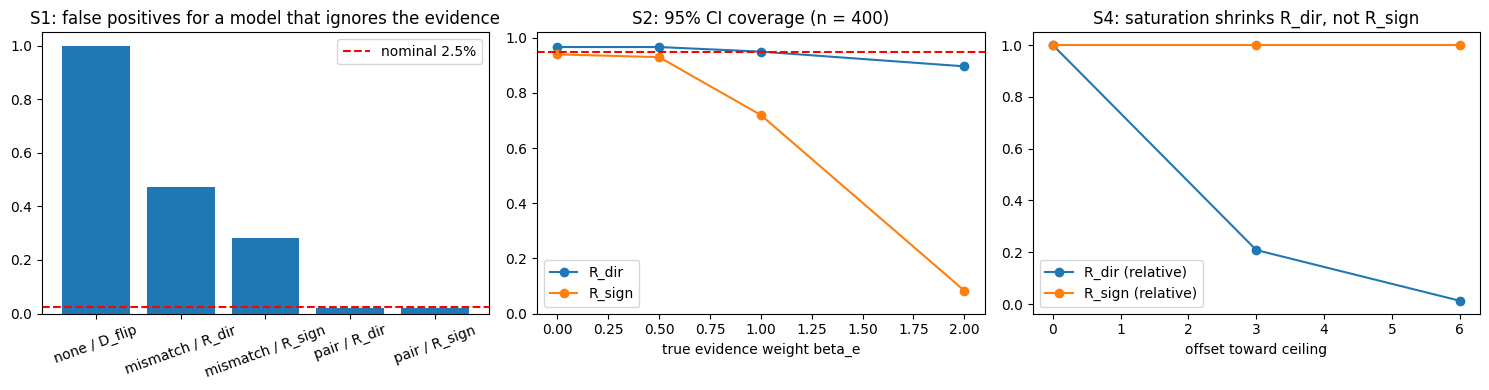

runtime 1.2 min


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
s1 = S1.copy(); s1["label"] = s1["control"] + " / " + s1["estimator"]
ax[0].bar(s1["label"], s1["reject_H0"]); ax[0].axhline(0.025, color="r", ls="--", label="nominal 2.5%")
ax[0].set_title("S1: false positives for a model that ignores the evidence"); ax[0].tick_params(axis="x", rotation=20); ax[0].legend()
for est in ["R_dir", "R_sign"]:
    s = S2[(S2.estimator == est) & (S2.n == 400)]
    ax[1].plot(s["beta_e"], s["coverage"], "o-", label=est)
ax[1].axhline(0.95, color="r", ls="--"); ax[1].set_ylim(0, 1.02); ax[1].set_xlabel("true evidence weight beta_e")
ax[1].set_title("S2: 95% CI coverage (n = 400)"); ax[1].legend()
s4 = S4[S4.temperature == 1.0]
ax[2].plot(s4["offset"], s4["true_R_dir"] / s4["true_R_dir"].iloc[0], "o-", label="R_dir (relative)")
ax[2].plot(s4["offset"], s4["true_R_sign"] / s4["true_R_sign"].iloc[0], "o-", label="R_sign (relative)")
ax[2].set_xlabel("offset toward ceiling"); ax[2].set_title("S4: saturation shrinks R_dir, not R_sign"); ax[2].legend()
plt.tight_layout(); plt.savefig(f"{OUT}/sim06.png", dpi=110); plt.show()
print(f"runtime {(time.time() - T0) / 60:.1f} min")

## Reading the results
- **S1:** naive and mismatched-control estimators should reject far above 2.5% for a blind model; the exact-gap pair control should stay near nominal. This justifies the design choice made in notebook 03.
- **S2:** coverage near 0.95 and bias near 0 for our estimator, at all n.
- **S3:** estimates shrink by about (1 - q) - real-data estimates on text-mined labels are lower bounds.
- **S4:** R_dir changes with calibration and goes to 0 at the ceiling even though the ranking is unchanged; R_sign is
  invariant to temperature (a monotone transform). This is the formal basis for reporting both.
- **S5:** with the marker following the label, R_dir measures the marker, not the evidence.